# 04 · Motion adaptation, history and personal calibration

**Starting point:** frozen image features did not beat the median reference.  
**Question:** can video pretraining, longer history or personal calibration improve transfer?

Run All reads saved predictions. It does not retrain or change the app.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "training/notebooks").is_dir()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from training.reporting import (
    RUNS,
    LABELS,
    result_folder,
    load_predictions,
    assert_matched_examples,
    regression_report,
    classification_report,
    metrics_table,
    plot_errors,
    plot_participants,
    plot_diagnostics,
    plot_warnings,
)

OUTPUT = ROOT / "training/artifacts/submission_report"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 44)


## Experiment 3 · Pretrained video motion

**Why:** individual-frame features may miss temporal movement.  
**Change:** use Kinetics-pretrained R3D-18, compare its frozen representation with a rank-4 adapter in its final block, using the same TCN head and four-rep history. This tunes an adapter, not the entire backbone.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Motion adaptation,Adapted R3D · last 4 reps,124,6,3,4.811,0.102,5.828,0.175,0.322,-0.870,-0.977,6
1,Motion adaptation,Frozen R3D + TCN,124,6,3,4.889,0.117,5.933,0.184,0.324,-0.893,-1.050,6
2,Motion adaptation,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6


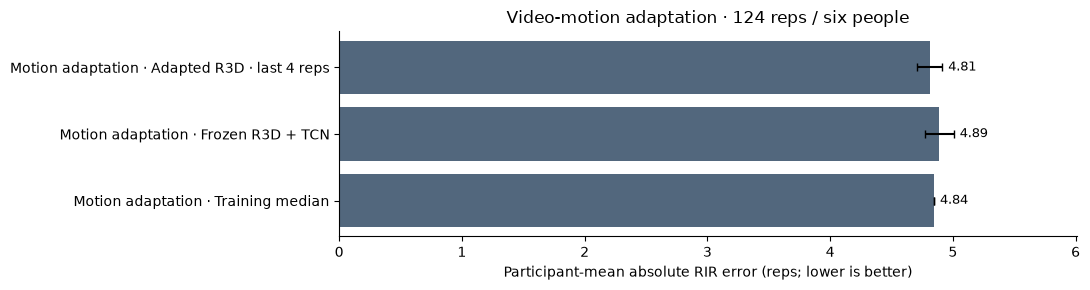

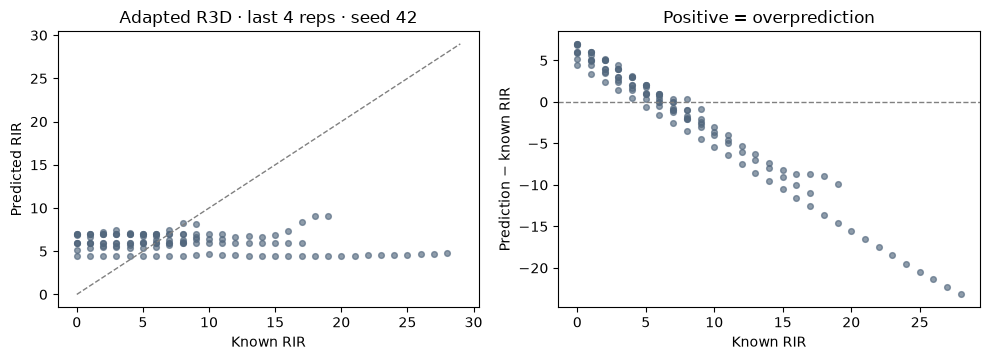

In [2]:
adaptation_predictions = load_predictions(ROOT, "adaptation", "Motion adaptation")
assert_matched_examples(adaptation_predictions)
adaptation_scores, adaptation_people = regression_report(adaptation_predictions)
display(metrics_table(adaptation_scores))
plot_errors(
    adaptation_scores,
    "Video-motion adaptation · 124 reps / six people",
    OUTPUT / "04_adaptation.png",
)
plt.show()
plot_diagnostics(
    adaptation_predictions, "r3d_adapter_tcn", OUTPUT / "04_prediction_errors.png"
)
plt.show()
adaptation_scores.to_csv(OUTPUT / "04_adaptation_metrics.csv", index=False)


**Result:** adapted R3D MAE ≈ 4.81 versus frozen R3D ≈ 4.89 and median ≈ 4.84. The gain is small and within-one-rep performance remains weak. Near-constant predictions remain visible.  
**Next question:** does using every completed rep help more than the latest four?

## Experiment 4 · Longer causal history

**Why:** fatigue develops over several reps.  
**Change:** compare four completed reps against all completed reps up to the current rep. Later repetitions are not prediction inputs.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,History length,Adapted R3D · last 4 reps,124,6,3,4.811,0.102,5.828,0.175,0.322,-0.870,-0.977,6
1,History length,Adapted R3D · all previous reps,124,6,3,5.232,0.136,6.072,0.155,0.288,-1.729,-1.382,6
2,History length,Training median,124,6,3,4.845,0.000,5.883,0.209,0.348,-0.532,-1.086,6


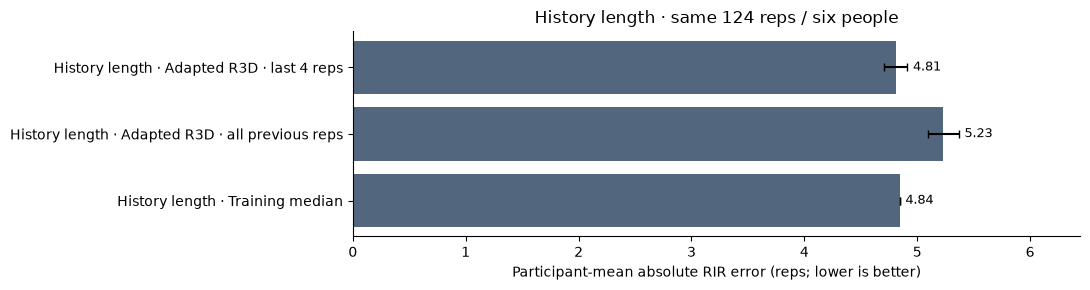

In [3]:
history_predictions = load_predictions(ROOT, "history", "History length")
assert_matched_examples(history_predictions)
history_scores, history_people = regression_report(history_predictions)
display(metrics_table(history_scores))
plot_errors(
    history_scores,
    "History length · same 124 reps / six people",
    OUTPUT / "04_history.png",
)
plt.show()
history_scores.to_csv(OUTPUT / "04_history_metrics.csv", index=False)


**Result:** full-prefix MAE ≈ 5.23, worse than the four-rep adapter. More history did not improve this experiment.  
**Next question:** can one known set help adapt predictions to the same person?

## Experiment 5 · One-set personal calibration

**Why:** people can have different movement patterns.  
**Change:** adapt an offset or regularized output head using one labeled set, then test on a different set from that person. The population model excludes both of that person's sets. Three paired people are available. Set chronology and matched loads are unverified.

Keep this different evaluation protocol separate from population testing.

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Calibration S01 → S02,Calibration median,41,3,3,3.842,0.000,4.621,0.217,0.375,-2.167,-0.331,3
1,Calibration S01 → S02,General video model,41,3,3,3.868,0.099,4.601,0.196,0.329,-0.301,-0.512,3
2,Calibration S01 → S02,Personal offset,41,3,3,3.871,0.007,4.635,0.196,0.341,-2.178,-0.339,3
3,Calibration S01 → S02,Personal ridge head,41,3,3,4.357,0.475,5.054,0.136,0.280,-1.448,-0.743,3
4,Calibration S01 → S02,Previous set capacity,41,3,3,5.033,0.000,5.652,0.158,0.237,-5.033,-0.954,3


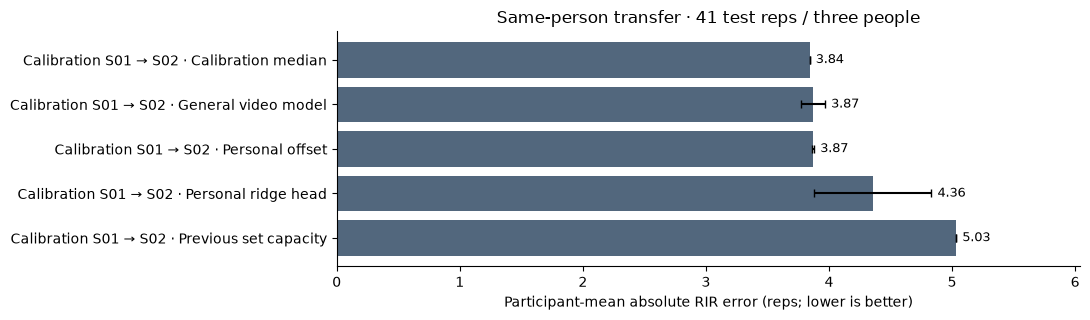

,condition,model,examples,people,seeds,mae,mae_seed_sd,rmse,within_1,within_2,bias,r2,r2_people
0,Reverse-direction sensitivity,Calibration median,19,3,3,5.167,0.000,5.497,0.056,0.111,5.167,-8.664,3
1,Reverse-direction sensitivity,General video model,19,3,3,3.300,0.308,3.754,0.172,0.347,3.272,-3.617,3
2,Reverse-direction sensitivity,Personal offset,19,3,3,5.023,0.195,5.355,0.056,0.111,5.023,-8.221,3
3,Reverse-direction sensitivity,Personal ridge head,19,3,3,3.371,1.412,3.575,0.156,0.373,3.249,-4.549,3
4,Reverse-direction sensitivity,Previous set capacity,19,3,3,7.333,0.000,7.333,0.000,0.000,7.333,-17.619,3


In [4]:
personal_predictions = load_predictions(
    ROOT, "personalization", "Calibration S01 → S02", direction="S01_to_S02"
)
assert_matched_examples(personal_predictions)
personal_scores, personal_people = regression_report(personal_predictions)
display(metrics_table(personal_scores))
plot_errors(
    personal_scores,
    "Same-person transfer · 41 test reps / three people",
    OUTPUT / "04_personalization.png",
)
plt.show()
reverse_predictions = load_predictions(
    ROOT,
    "personalization",
    "Reverse-direction sensitivity",
    direction="S02_to_S01_sensitivity",
)
assert_matched_examples(reverse_predictions)
reverse_scores, reverse_people = regression_report(reverse_predictions)
display(metrics_table(reverse_scores))
pd.concat([personal_scores, reverse_scores]).to_csv(
    OUTPUT / "04_personalization_metrics.csv", index=False
)


**Result:** the calibrated head worsened primary held-out-set MAE (≈ 4.36 versus 3.87 for the general model). Fitting the calibration recording did not ensure transfer.  
**Next question:** can the simpler near-failure decision work better? See notebook 05. These RIR scores do not establish a tremor benefit.

## Reading the metrics

Metrics average each participant equally, then average training seeds. **MAE** is mean absolute error in reps; **RMSE** gives more weight to large errors. **Within 1/2** is the fraction within one/two reps. **Bias** is predicted minus known RIR: positive means too many reps predicted. R² compares with variation in known RIR; it can be negative and is undefined for a person with only one example. Seed standard deviation is not a confidence interval; one seed gives no estimate of training variability.

## Reproduce experiments · optional

Flags are independent. Cached features are reused. Enable history mode only for a new history comparison.

In [5]:
RUN_ADAPTATION = False
RUN_PERSONALIZATION = False
EXPORT_R3D_DEMO = False
R3D_HISTORY_EXPERIMENT = False

In [6]:
if RUN_ADAPTATION or RUN_PERSONALIZATION or EXPORT_R3D_DEMO:
    from pathlib import Path
    from datetime import datetime, timezone
    from importlib.metadata import version
    import os
    os.environ["WANDB_DISABLE_CODE"] = "true"
    os.environ["WANDB_DISABLE_GIT"] = "true"
    os.environ["OTEL_SDK_DISABLED"] = "true"
    import copy
    import hashlib
    import json
    import random
    import time
    
    import cv2
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")
    import matplotlib.pyplot as plt
    import torch
    from torch import nn
    from torch.nn import functional as F
    from torch.utils.data import Dataset, DataLoader
    from torchvision.models import resnet18, ResNet18_Weights
    import wandb
    from IPython.display import display
    
    RUN_MODE = "pilot"
    RESUME_RUN_DIR = None
    WANDB_MODE = "offline"
    WANDB_PROJECT = "replens-video-pilot"
    MODEL_NAMES = ["tcn", "lstm"]
    HIDDEN_SIZE = 64
    BATCH_SIZE = 4
    ENCODER_BATCH_SIZE = 16
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 0.0001
    PATIENCE = 5
    
    if RUN_MODE not in {"smoke", "pilot"} or WANDB_MODE not in {"offline", "online", "disabled"}:
        raise ValueError("Choose a supported run/tracking mode.")
    if not MODEL_NAMES or not set(MODEL_NAMES).issubset({"tcn", "lstm"}):
        raise ValueError("Choose tcn and/or lstm.")
    MAX_EPOCHS = 2 if RUN_MODE == "smoke" else 25
    SEEDS = [42] if RUN_MODE == "smoke" else [42, 43, 44]
    ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                 if (path / ".git").is_dir() and (path / "training" / "notebooks").is_dir()), None)
    if ROOT is None:
        raise RuntimeError("Open this notebook from the RepLens project folder.")
    DATA_DIR = ROOT / "training" / "data"
    VIDEO_VARIANT = "cropped"
    VIDEO_DIR = DATA_DIR / ("cropped_videos" if VIDEO_VARIANT == "cropped" else "videos")
    MODEL_DIR = ROOT / "training" / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    torch.hub.set_dir(str(MODEL_DIR / "torch"))
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    cv2.setNumThreads(1)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    
    def sha256_file(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)
        return digest.hexdigest()
    
    
    candidates = sorted((DATA_DIR / "prepared").glob("history_*_reps/*/preparation.json"), key=lambda path: path.stat().st_mtime, reverse=True)
    label_hash = sha256_file(DATA_DIR / "processed" / "reviewed_reps.csv")
    inventory_hash = sha256_file(DATA_DIR / "video_manifest.csv")
    PREPARATION_DIR = None
    for candidate in candidates:
        report = json.loads(candidate.read_text())
        config = report["configuration"]
        if (config["label_sha256"] == label_hash and config["inventory_sha256"] == inventory_hash
                and config.get("candidate_sha256") == sha256_file(DATA_DIR / "processed" / "candidate_reps.csv")
                and config.get("video_variant", "original") == VIDEO_VARIANT
                and (VIDEO_VARIANT != "cropped" or config.get("crop_exports_sha256") == sha256_file(DATA_DIR / "review/whole_lifter_crops/exports.json"))):
            PREPARATION_DIR = candidate.parent
            break
    if PREPARATION_DIR is None:
        raise RuntimeError("No preparation matches the current reviews. Run notebook 02 again.")
    print("Video framing:", VIDEO_VARIANT)
    windows = pd.read_csv(PREPARATION_DIR / "windows.csv")
    inference_windows = pd.read_csv(PREPARATION_DIR / "inference_windows.csv")
    if not inference_windows.empty and inference_windows.reps_left.notna().any():
        raise ValueError("Prediction-only windows must not contain training targets.")
    encoding_windows = pd.concat([windows, inference_windows], ignore_index=True)
    folds = json.loads((PREPARATION_DIR / "folds.json").read_text())
    with np.load(PREPARATION_DIR / "timestamps.npz", allow_pickle=False) as arrays:
        timestamps = {key: arrays[key].copy() for key in arrays.files}
    if RUN_MODE == "smoke":
        folds = folds[:1]
    if windows.empty or not np.isfinite(windows.reps_left).all():
        raise ValueError("Training windows/targets are missing or invalid.")
    DATASET_SCOPE = config.get("dataset_scope", "confirmed")
    accepted_labels = ["collector_confirmed_failure", "reviewer_confirmed_failure"]
    if DATASET_SCOPE == "exploratory":
        accepted_labels.append("user_reported_failure")
        print("EXPLORATORY: some targets use user-reported endpoints; public-source reuse permission is unverified.")
    if not windows.rir_label_status.isin(accepted_labels).all():
        raise ValueError("Resolve unsupported labels before training.")
    for _, group in encoding_windows.groupby("video_id"):
        source = (VIDEO_DIR / group.relative_path.iloc[0]).resolve()
        if not source.is_relative_to(VIDEO_DIR.resolve()) or sha256_file(source) != group.video_sha256.iloc[0]:
            raise ValueError("A source video changed after preparation.")
    for fold in folds:
        outer, test = set(fold["outer_train_participants"]), set(fold["test_participants"])
        if not outer.isdisjoint(test):
            raise ValueError("Participant leakage in outer folds.")
        for inner in fold["inner_validation"]:
            train, validation = set(inner["train_participants"]), set(inner["validation_participants"])
            if not train.isdisjoint(validation) or train | validation != outer:
                raise ValueError("Invalid inner validation split.")
    print(f"Mode: {RUN_MODE} | Device: {DEVICE} | Windows: {len(windows)} | Outer folds: {len(folds)}")
    print("Preparation:", PREPARATION_DIR.name)
    print(f"Prediction-only windows: {len(inference_windows)} across {inference_windows.video_id.nunique()} clips; excluded from training and accuracy.")
    
    print(f"Training dataset: {windows.video_id.nunique()} clips, {windows.participant_id.nunique()} people, {len(windows)} labeled reps.")


In [7]:
if RUN_ADAPTATION or RUN_PERSONALIZATION or EXPORT_R3D_DEMO:
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    
    
    class VideoWindows(Dataset):
        def __init__(self, table):
            self.table = table.reset_index(drop=True)
    
        def __len__(self):
            return len(self.table)
    
        def __getitem__(self, index):
            row = self.table.iloc[index]
            start, stop = int(row.frame_start), int(row.frame_stop_exclusive)
            values = features[row.video_id][start:stop]
            times = timestamps[row.video_id][start:stop]
            if not len(values) or len(values) != len(times) or times[-1] > row.clip_end_s or times[0] < row.clip_start_s:
                raise ValueError("Empty or noncausal video window.")
            return torch.from_numpy(values.copy()), float(row.reps_left)
    
    
    def collate_windows(batch):
        sequences, targets = zip(*batch)
        lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
        padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
        return padded, lengths, torch.tensor(targets, dtype=torch.float32)
    
    
    def make_loader(table, shuffle, seed):
        generator = torch.Generator().manual_seed(seed)
        return DataLoader(VideoWindows(table), batch_size=BATCH_SIZE, shuffle=shuffle,
                          num_workers=0, collate_fn=collate_windows, generator=generator)
    
    
    class CausalBlock(nn.Module):
        def __init__(self, channels, dilation):
            super().__init__()
            self.padding = 2 * dilation
            self.conv = nn.Conv1d(channels, channels, kernel_size=3, dilation=dilation)
            self.dropout = nn.Dropout(0.1)
    
        def forward(self, values):
            return values + self.dropout(F.relu(self.conv(F.pad(values, (self.padding, 0)))))
    
    
    class TemporalRegressor(nn.Module):
        def __init__(self, family, hidden_size):
            super().__init__()
            self.family = family
            self.project = nn.Sequential(nn.LayerNorm(512), nn.Linear(512, hidden_size), nn.ReLU())
            if family == "tcn":
                self.temporal = nn.Sequential(*[CausalBlock(hidden_size, dilation) for dilation in [1, 2, 4, 8, 16]])
            elif family == "lstm":
                self.temporal = nn.LSTM(hidden_size, hidden_size, batch_first=True)
            else:
                raise ValueError("Unknown temporal model.")
            self.output = nn.Linear(hidden_size, 1)
    
        def forward(self, values, lengths):
            projected = self.project(values)
            if self.family == "tcn":
                encoded = self.temporal(projected.transpose(1, 2)).transpose(1, 2)
                mask = torch.arange(values.shape[1], device=values.device)[None, :] < lengths[:, None]
                pooled = (encoded * mask.unsqueeze(-1)).sum(dim=1) / lengths[:, None]
            else:
                encoded, _ = self.temporal(projected)
                pooled = encoded[torch.arange(len(values), device=values.device), lengths - 1]
            return self.output(pooled).squeeze(-1)
    
    
    def predict(model, table):
        model.eval()
        values = []
        with torch.inference_mode():
            for frames, lengths, _ in make_loader(table, False, 0):
                values.extend(model(frames.to(DEVICE), lengths.to(DEVICE)).cpu().numpy().tolist())
        output = np.asarray(values, dtype=float)
        if output.shape != (len(table),) or not np.isfinite(output).all():
            raise ValueError("Invalid model predictions.")
        return output
    
    
    def metrics(table, predictions):
        truth = table.reps_left.to_numpy(dtype=float)
        predictions = np.asarray(predictions, dtype=float)
        if truth.shape != predictions.shape or not np.isfinite(predictions).all():
            raise ValueError("Each example requires one finite prediction.")
        error = predictions - truth
        person = pd.DataFrame({"participant": table.participant_id.to_numpy(), "absolute_error": np.abs(error)})
        return {"mae_reps": float(np.abs(error).mean()),
                "participant_mean_mae_reps": float(person.groupby("participant").absolute_error.mean().mean()),
                "rmse_reps": float(np.sqrt(np.mean(error ** 2))), "within_one_rep": float((np.abs(error) <= 1).mean()),
                "signed_error_reps": float(error.mean())}
    
    
    def fit_head(family, train_table, validation_table, epochs, seed, run, stage):
        set_seed(seed)
        model = TemporalRegressor(family, HIDDEN_SIZE).to(DEVICE)
        with torch.no_grad():
            model.output.bias.fill_(float(train_table.reps_left.mean()))
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        criterion = nn.SmoothL1Loss()
        history, best_state = [], None
        best_score, best_epoch, waiting = float("inf"), 0, 0
        run.define_metric(f"{stage}/epoch")
        run.define_metric(f"{stage}/*", step_metric=f"{stage}/epoch")
        for epoch in range(1, epochs + 1):
            model.train()
            loss_total, count = 0.0, 0
            for frames, lengths, targets in make_loader(train_table, True, seed + epoch):
                optimizer.zero_grad(set_to_none=True)
                prediction = model(frames.to(DEVICE), lengths.to(DEVICE))
                loss = criterion(prediction, targets.to(DEVICE))
                if not torch.isfinite(loss):
                    raise ValueError("Training loss became nonfinite.")
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                loss_total += float(loss.detach().cpu()) * len(targets)
                count += len(targets)
            entry = {"stage": stage, "epoch": epoch, "train_loss": loss_total / count}
            log = {f"{stage}/epoch": epoch, f"{stage}/train_loss": entry["train_loss"]}
            if validation_table is not None:
                score = metrics(validation_table, predict(model, validation_table))["participant_mean_mae_reps"]
                entry["validation_mae_reps"] = score
                log[f"{stage}/validation_mae_reps"] = score
                if score < best_score - 1e-4:
                    best_score, best_epoch, waiting = score, epoch, 0
                    best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
                else:
                    waiting += 1
            run.log(log)
            history.append(entry)
            if validation_table is not None and waiting >= PATIENCE:
                break
        if validation_table is not None:
            if best_state is None:
                raise ValueError("No finite validation checkpoint.")
            model.load_state_dict(best_state)
        else:
            best_epoch = epochs
        return model, best_epoch, history


In [8]:
if RUN_ADAPTATION or RUN_PERSONALIZATION or EXPORT_R3D_DEMO:
    RUN_R3D_ADAPTATION = False
    R3D_MAX_EPOCHS = 12
    R3D_PATIENCE = 3
    R3D_SEEDS = [42, 43, 44]
    R3D_RANK = 4
    R3D_BATCH_SIZE = 4
    
    
    
    from torchvision.models.video import r3d_18, R3D_18_Weights
    
    class FinalBlockAdapter(nn.Module):
        def __init__(self, adapted):
            super().__init__()
            self.adapted = adapted
            self.down = nn.Conv3d(512, R3D_RANK, 1, bias=False)
            self.up = nn.Conv3d(R3D_RANK, 512, 3, padding=1, bias=False)
            nn.init.normal_(self.down.weight, std=.01)
            nn.init.zeros_(self.up.weight)
            self.down.requires_grad_(adapted)
            self.up.requires_grad_(adapted)
            self.head = TemporalRegressor("tcn", 24)
    
        def forward(self, activations, base, lengths):
            if self.adapted:
                base = base + self.up(F.relu(self.down(activations)))
            tokens = F.relu(base).mean(dim=(2, 3, 4))
            sequences = torch.split(tokens, lengths.tolist())
            padded = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
            return self.head(padded, lengths)
    
    
    def r3d_loader(table, shuffle, seed, history_mode="rolling4"):
        class Windows(Dataset):
            def __len__(self):
                return len(table)
            def __getitem__(self, index):
                row = table.iloc[index]
                history = r3d_marks[row.video_id]
                position = history.index(int(row.rep))
                indices = history[0 if history_mode == "prefix" else max(0,position-3):position+1]
                a = np.concatenate([r3d_features[(row.video_id,k)][0] for k in indices])
                b = np.concatenate([r3d_features[(row.video_id,k)][1] for k in indices])
                count = int(table.participant_id.eq(row.participant_id).sum())
                weight = len(table) / (table.participant_id.nunique() * count)
                return torch.from_numpy(a).float(), torch.from_numpy(b).float(), float(row.reps_left), weight
        def collate(batch):
            a,b,targets,weights=zip(*batch)
            return torch.cat(a),torch.cat(b),torch.tensor([len(x) for x in a]),torch.tensor(targets),torch.tensor(weights)
        return DataLoader(Windows(),batch_size=R3D_BATCH_SIZE,shuffle=shuffle,num_workers=0,
                          collate_fn=collate,generator=torch.Generator().manual_seed(seed))
    
    
    def r3d_predict(model, table):
        model.eval()
        values=[]
        with torch.inference_mode():
            for a,b,lengths,_,_ in r3d_loader(table,False,0,getattr(model,"history_mode","rolling4")):
                values.extend(model(a.to(DEVICE),b.to(DEVICE),lengths.to(DEVICE)).cpu().tolist())
        result=np.asarray(values,float)
        if result.shape!=(len(table),) or not np.isfinite(result).all():
            raise ValueError("Invalid R3D predictions.")
        return result
    
    
    def fit_r3d(condition, train, validation, epochs, seed):
        set_seed(seed)
        model=FinalBlockAdapter(condition.startswith("r3d_adapter")).to(DEVICE)
        model.history_mode = "prefix" if condition.endswith("_prefix") else "rolling4"
        median=float(train.reps_left.median())
        with torch.no_grad():
            model.head.output.weight.zero_()
            model.head.output.bias.fill_(median)
        groups=[{"params":model.head.parameters(),"lr":.001}]
        if model.adapted:
            groups.append({"params":[*model.down.parameters(),*model.up.parameters()],"lr":.0003})
        optimizer=torch.optim.AdamW(groups,weight_decay=.001)
        # Identical targets and sampling for both conditions; no test-person tuning.
        best_state=None;best_score=float("inf");best_epoch=0;waiting=0;curve=[]
        if validation is not None:
            initial=r3d_predict(model,validation)
            best_score=metrics(validation,initial)["participant_mean_mae_reps"]
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        for epoch in range(1,epochs+1):
            model.train();loss_sum=0.;seen=0
            for a,b,lengths,target,weights in r3d_loader(train,True,seed+epoch,model.history_mode):
                optimizer.zero_grad(set_to_none=True)
                prediction=model(a.to(DEVICE),b.to(DEVICE),lengths.to(DEVICE))
                loss=(F.smooth_l1_loss(prediction,target.to(DEVICE),reduction="none")*weights.to(DEVICE)).mean()
                if not torch.isfinite(loss):
                    raise ValueError("Nonfinite R3D loss.")
                loss.backward();nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],1.)
                optimizer.step();loss_sum+=float(loss.detach().cpu())*len(target);seen+=len(target)
            entry={"epoch":epoch,"train_loss":loss_sum/seen}
            if validation is not None:
                score=metrics(validation,r3d_predict(model,validation))["participant_mean_mae_reps"]
                entry["validation_participant_mae"]=score
                if score<best_score-1e-4:
                    best_score=score;best_epoch=epoch;waiting=0
                    best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                else:
                    waiting+=1
            curve.append(entry)
            if validation is not None and waiting>=R3D_PATIENCE:
                break
        if validation is not None:
            model.load_state_dict(best_state)
        else:
            best_epoch=epochs
        return model,best_epoch,curve


In [9]:
if RUN_ADAPTATION or RUN_PERSONALIZATION or EXPORT_R3D_DEMO:
    RUN_R3D_ADAPTATION = True
    if RUN_R3D_ADAPTATION:
        r3d_dir=ROOT/"training/artifacts"/(("r3d_history_" if R3D_HISTORY_EXPERIMENT else "r3d_adaptation_")+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
        r3d_dir.mkdir()
        r3d_contract={"encoder":"r3d18_kinetics400_v1", "weights_sha256":sha256_file(MODEL_DIR/"torch/checkpoints/r3d_18-b3b3357e.pth"),
            "preprocessing":"native_frames_rgb_aspect_pad112_kinetics_norm_v1", "chunk_frames":16,
            "partial_chunk_padding":"repeat_last_observed_frame", "cache_point":"final_block_conv1_and_pre_relu_sum_v1",
            "video_variant":VIDEO_VARIANT, "torch":str(torch.__version__)}
        cache_id=hashlib.sha256(json.dumps(r3d_contract,sort_keys=True).encode()).hexdigest()[:16]
        cache_dir=DATA_DIR/"r3d_adaptation_cache"/cache_id;cache_dir.mkdir(parents=True,exist_ok=True)
        r3d_marks={};r3d_features={};r3d_cache_records=[]
        marks=pd.read_csv(DATA_DIR/"processed/reviewed_reps.csv")
        backbone=r3d_18(weights=R3D_18_Weights.KINETICS400_V1).eval().requires_grad_(False).to(DEVICE)
        def encode_chunks(chunks):
            a_values=[];b_values=[]
            with torch.inference_mode():
                for start in range(0,len(chunks),8):
                    x=torch.stack(chunks[start:start+8]).to(DEVICE)
                    for layer in [backbone.stem,backbone.layer1,backbone.layer2,backbone.layer3,backbone.layer4[0]]:
                        x=layer(x)
                    block=backbone.layer4[1]
                    a=block.conv1(x)
                    b=block.conv2(a)+x
                    expected=block.relu(b.clone()).mean((2,3,4))
                    actual=F.relu(b).mean((2,3,4))
                    torch.testing.assert_close(actual,expected)
                    a_values.append(a.cpu().numpy().astype(np.float16))
                    b_values.append(b.cpu().numpy().astype(np.float16))
            return np.concatenate(a_values),np.concatenate(b_values)
        def prepare_r3d(frame):
            h,w=frame.shape[:2];scale=112/max(h,w)
            image=cv2.resize(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB),(max(1,round(w*scale)),max(1,round(h*scale))))
            canvas=np.empty((112,112,3),np.uint8);canvas[:]=[110,101,96]
            y,x=(112-image.shape[0])//2,(112-image.shape[1])//2
            canvas[y:y+image.shape[0],x:x+image.shape[1]]=image
            value=torch.from_numpy(canvas).permute(2,0,1).float()/255
            return (value-torch.tensor([.43216,.394666,.37645])[:,None,None])/torch.tensor([.22803,.22145,.216989])[:,None,None]
        for video_id,table in windows.groupby("video_id",sort=False):
            table=table.sort_values("rep");source=VIDEO_DIR/table.iloc[0].relative_path
            digest=sha256_file(source)
            if digest!=table.iloc[0].video_sha256:
                raise ValueError("Video changed after preparation.")
            reps=marks.loc[marks.video_id.eq(video_id)].sort_values("rep")
            r3d_marks[video_id]=reps.rep.astype(int).tolist()
            capture=cv2.VideoCapture(str(source))
            try:
                for row in reps.itertuples():
                    times=timestamps[video_id]
                    first=int(np.searchsorted(times,row.start_s,"left"));stop=int(np.searchsorted(times,row.end_s,"right"))
                    identity=f"{digest}|{first}|{stop}|{cache_id}"
                    cache=cache_dir/(hashlib.sha256(identity.encode()).hexdigest()+".npz")
                    if cache.exists():
                        with np.load(cache,allow_pickle=False) as saved:
                            a=saved["activations"].copy();b=saved["base"].copy()
                            if str(saved["identity"].item())!=identity:
                                raise ValueError("Mismatched activation cache.")
                    else:
                        capture.set(cv2.CAP_PROP_POS_FRAMES,first)
                        tensors=[]
                        for index in range(first,stop):
                            ok,frame=capture.read()
                            if not ok:
                                raise ValueError("Missing frames in a reviewed repetition.")
                            decoded_time=capture.get(cv2.CAP_PROP_POS_MSEC)/1000
                            if abs(decoded_time-times[index])>.003:
                                raise ValueError("Decoder timing disagrees with prepared frame index.")
                            tensors.append(prepare_r3d(frame))
                        if not tensors:
                            raise ValueError("Empty repetition.")
                        chunks=[]
                        for offset in range(0,len(tensors),16):
                            chunk=tensors[offset:offset+16]
                            chunk=chunk+[chunk[-1]]*(16-len(chunk))
                            chunks.append(torch.stack(chunk).permute(1,0,2,3))
                        a,b=encode_chunks(chunks)
                        np.savez_compressed(cache,activations=a,base=b,identity=np.array(identity))
                    if a.shape!=b.shape or a.shape[1:]!=(512,2,7,7) or not np.isfinite(a).all() or not np.isfinite(b).all():
                        raise ValueError("Invalid frozen-prefix cache.")
                    r3d_features[(video_id,int(row.rep))]=(a,b)
                    r3d_cache_records.append({"video_id":video_id,"rep":int(row.rep),"start_frame":first,"stop_frame_exclusive":stop,"chunks":len(a),"source_sha256":digest})
            finally:
                capture.release()
            print("Cached native-frame motion activations:",source.name,flush=True)
        backbone.to("cpu");del backbone
        if DEVICE.type=="mps":
            torch.mps.empty_cache()
        pd.DataFrame(r3d_cache_records).to_csv(r3d_dir/"cache_index.csv",index=False)
        config={"encoder":r3d_contract,"preparation_id":PREPARATION_DIR.name,"scope":DATASET_SCOPE,
            "participants":sorted(windows.participant_id.unique().tolist()),"reps":len(windows),"seeds":R3D_SEEDS,
            "max_epochs":R3D_MAX_EPOCHS,"patience":R3D_PATIENCE,"adapter_rank":R3D_RANK,"head_hidden_size":24,
            "conditions":(["r3d_adapter_tcn","r3d_adapter_tcn_prefix"] if R3D_HISTORY_EXPERIMENT else ["r3d_frozen_tcn","r3d_adapter_tcn"]),
            "history_modes":["rolling4","prefix"] if R3D_HISTORY_EXPERIMENT else ["rolling4"],"history_reps":None if R3D_HISTORY_EXPERIMENT else 4,
            "note":"Retrospective whole-lifter crops; no physiological tremor validation or live causal crop claim."}
        (r3d_dir/"config.json").write_text(json.dumps(config,indent=2)+"\n")
        print("Prepared",len(r3d_features),"repetitions. Run:",r3d_dir,flush=True)
    else:
        print("Enable RUN_R3D_ADAPTATION to encode videos for the controlled adapter experiment.")
    
    RUN_R3D_ADAPTATION = RUN_ADAPTATION


In [10]:
if RUN_ADAPTATION:
    if RUN_R3D_ADAPTATION:
        results=[];curves=[];selections=[]
        for fold_number,fold in enumerate(folds,1):
            train=windows.loc[windows.participant_id.isin(fold["outer_train_participants"])]
            test=windows.loc[windows.participant_id.isin(fold["test_participants"])]
            for seed in R3D_SEEDS:
                output=test[["sample_id","video_id","participant_id","set_id","rep","reps_left"]].copy()
                output["prediction"]=float(train.reps_left.median());output["model"]="training_median"
                output["seed"]=seed;output["fold_id"]=fold["fold_id"];results.append(output)
                for condition in config["conditions"]:
                    print(f"R3D fold {fold_number}/{len(folds)}, {condition}, seed {seed}",flush=True)
                    selected=[]
                    for inner_number,inner in enumerate(fold["inner_validation"],1):
                        inner_train=train.loc[train.participant_id.isin(inner["train_participants"])]
                        validation=train.loc[train.participant_id.isin(inner["validation_participants"])]
                        model,epoch,curve=fit_r3d(condition,inner_train,validation,R3D_MAX_EPOCHS,seed)
                        selected.append(epoch)
                        selections.append({"model":condition,"seed":seed,"fold_id":fold["fold_id"],"inner":inner_number,"best_epoch":epoch})
                        curves.extend([{**r,"model":condition,"seed":seed,"fold_id":fold["fold_id"],"stage":f"inner_{inner_number}"} for r in curve])
                        del model
                    epochs=max(0,int(np.median(selected)))
                    model,_,curve=fit_r3d(condition,train,None,epochs,seed)
                    predicted=r3d_predict(model,test)
                    output=test[["sample_id","video_id","participant_id","set_id","rep","reps_left"]].copy()
                    output["prediction"]=predicted;output["model"]=condition;output["seed"]=seed;output["fold_id"]=fold["fold_id"]
                    results.append(output)
                    curves.extend([{**r,"model":condition,"seed":seed,"fold_id":fold["fold_id"],"stage":"outer_refit"} for r in curve])
                    torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},"condition":condition,
                        "rank":R3D_RANK,"head_hidden_size":24,"encoder_contract":r3d_contract,"fold":fold,"seed":seed,
                        "refit_epochs":epochs,"history_mode":model.history_mode,"preparation_id":PREPARATION_DIR.name,"deployment_approved":False},
                        r3d_dir/f"{condition}_{fold['fold_id']}_seed{seed}.pt")
                    print("  Held-out participant MAE:",round(metrics(test,predicted)["participant_mean_mae_reps"],3),"epochs",epochs,flush=True)
                    del model
                    pd.concat(results).to_csv(r3d_dir/"predictions.csv",index=False)
                    pd.DataFrame(curves).to_csv(r3d_dir/"learning_curves.csv",index=False)
                    pd.DataFrame(selections).to_csv(r3d_dir/"inner_selection.csv",index=False)
        combined=pd.concat(results)
        seed_rows=[{"model":family,"seed":int(seed),**metrics(table,table.prediction.to_numpy())}
                   for (family,seed),table in combined.groupby(["model","seed"])]
        scores=pd.DataFrame(seed_rows)
        comparison=scores.groupby("model").agg(participant_mae_mean=("participant_mean_mae_reps","mean"),
            participant_mae_seed_std=("participant_mean_mae_reps",lambda s:float(s.std(ddof=0))),
            rmse_mean=("rmse_reps","mean"),within_one_rep_mean=("within_one_rep","mean"))
        scores.to_csv(r3d_dir/"seed_scores.csv",index=False);comparison.to_csv(r3d_dir/"comparison.csv")
        display(comparison)
        run=wandb.init(project=WANDB_PROJECT,mode="offline",dir=str(r3d_dir),name="r3d-adapter-comparison",config=config,
                       settings=wandb.Settings(disable_git=True,disable_code=True,save_code=False,x_disable_stats=True))
        try:
            run.log({f"{model}/{metric}":float(value) for model,row in comparison.iterrows() for metric,value in row.items()})
        finally:
            run.finish()
        (r3d_dir/"status.json").write_text(json.dumps({"status":"completed","comparisons_saved":True,"deployment_approved":False},indent=2)+"\n")
        print("Completed R3D adapter comparison:",r3d_dir,flush=True)


In [11]:
PERSONAL_RIDGE_ALPHA = 10.0
if RUN_PERSONALIZATION:
    import itertools
    personal_dir=ROOT/"training/artifacts"/("personalization_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
    personal_dir.mkdir()
    source_run=ROOT/"training/artifacts/r3d_adaptation_20261030T180126927110Z"
    paired={}
    for person,table in windows.groupby("participant_id"):
        sets=table[["set_id","video_id"]].drop_duplicates().sort_values("set_id")
        if len(sets)==2:
            paired[person]=sets.video_id.tolist()
    if len(paired)<2:
        raise ValueError("Need at least two people with distinct calibration and test sets.")
    # Fixed before examining transfer results; no calibration hyperparameters are fitted on test sets.
    def fit_personal_head(hidden,base,target):
        mean=hidden.mean(0);scale=np.maximum(hidden.std(0),.05)
        z=np.column_stack([(hidden-mean)/scale,np.ones(len(hidden))])
        correction=np.linalg.solve(z.T@z+PERSONAL_RIDGE_ALPHA*np.eye(z.shape[1]),z.T@(target-base))
        return mean,scale,correction
    def predict_personal_head(hidden,base,parameters):
        mean,scale,correction=parameters
        return base+np.column_stack([(hidden-mean)/scale,np.ones(len(hidden))])@correction
    def hidden_and_prediction(model,table):
        values=[]
        hook=model.head.output.register_forward_pre_hook(lambda module,args:values.append(args[0].detach().cpu().numpy().copy()))
        try:
            predicted=r3d_predict(model,table)
        finally:
            hook.remove()
        hidden=np.concatenate(values).astype(float)
        if hidden.shape!=(len(table),24):
            raise ValueError("Unexpected prediction-head features.")
        return hidden,predicted
    rows=[];calibration_rows=[];verification=[]
    for person,video_ids in paired.items():
        for seed in [42,43,44]:
            checkpoint=source_run/f"r3d_adapter_tcn_test_{person}_seed{seed}.pt"
            saved=torch.load(checkpoint,map_location="cpu",weights_only=True)
            fold=saved["fold"]
            if person in fold["outer_train_participants"] or fold["test_participants"]!=[person]:
                raise ValueError("The base model was not trained independently of the calibration person.")
            model=FinalBlockAdapter(True).to(DEVICE)
            model.load_state_dict(saved["state_dict"]);model.history_mode="rolling4";model.eval()
            table=windows.loc[windows.participant_id.eq(person)].copy()
            hidden,base=hidden_and_prediction(model,table)
            table["base_prediction"]=base
            for direction,cal_id,test_id in [("S01_to_S02",video_ids[0],video_ids[1]),("S02_to_S01_sensitivity",video_ids[1],video_ids[0])]:
                cal_mask=table.video_id.eq(cal_id).to_numpy()
                test_mask=(table.video_id.eq(test_id)&table.rep.ge(4)).to_numpy()
                calibration=table.loc[cal_mask];test=table.loc[test_mask]
                if not len(calibration) or not len(test):
                    raise ValueError("Calibration and test sets require valid examples.")
                if set(calibration.video_id)&set(test.video_id):
                    raise ValueError("Calibration and test videos overlap.")
                cal_h=hidden[cal_mask];test_h=hidden[test_mask]
                cal_base=base[cal_mask];test_base=base[test_mask]
                cal_target=calibration.reps_left.to_numpy(float)
                bias=float(np.mean(cal_target-cal_base))
                parameters=fit_personal_head(cal_h,cal_base,cal_target)
                before=tuple(x.copy() for x in parameters)
                # Applying the head takes no test labels; modifying those labels cannot change its weights.
                personalized=predict_personal_head(test_h,test_base,parameters)
                assert all(np.array_equal(a,b) for a,b in zip(before,parameters))
                predictions={"general_r3d":test_base,
                    "personal_bias":test_base+bias,
                    "personal_ridge_head":personalized,
                    "calibration_median":np.full(len(test),np.median(cal_target)),
                    "previous_set_capacity":np.maximum(0,len(calibration)-test.rep.to_numpy())}
                for method,values in predictions.items():
                    if not np.isfinite(values).all():
                        raise ValueError("Invalid personalized predictions.")
                    for (_,example),prediction in zip(test.iterrows(),values):
                        rows.append({"direction":direction,"participant_id":person,"seed":seed,"method":method,
                            "calibration_video":cal_id,"test_video":test_id,"rep":int(example.rep),
                            "reps_left":float(example.reps_left),"prediction":float(prediction)})
                cal_pred=predict_personal_head(cal_h,cal_base,parameters)
                calibration_rows.append({"participant_id":person,"seed":seed,"direction":direction,
                    "calibration_video":cal_id,"calibration_reps":len(calibration),"test_video":test_id,"test_reps":len(test),
                    "calibration_general_mae":float(np.mean(np.abs(cal_base-cal_target))),
                    "calibration_personal_mae":float(np.mean(np.abs(cal_pred-cal_target)))})
                np.savez_compressed(personal_dir/f"{person}_{direction}_seed{seed}_head.npz",
                    mean=parameters[0],scale=parameters[1],correction=parameters[2],bias=np.array(bias),
                    calibration_video=np.array(cal_id),test_video=np.array(test_id))
                verification.append({"person":person,"seed":seed,"direction":direction,
                    "base_training_participants":fold["outer_train_participants"],"calibration_video":cal_id,"test_video":test_id})
            del model
            print("Personal transfer evaluated:",person,"seed",seed,flush=True)
    predictions=pd.DataFrame(rows);predictions.to_csv(personal_dir/"predictions.csv",index=False)
    calibration=pd.DataFrame(calibration_rows);calibration.to_csv(personal_dir/"calibration_fit.csv",index=False)
    predictions["absolute_error"]=(predictions.prediction-predictions.reps_left).abs()
    predictions["within_one"]=(predictions.absolute_error<=1).astype(float)
    individual=predictions.groupby(["direction","method","seed","participant_id"]).agg(
        mae_reps=("absolute_error","mean"),within_one=("within_one","mean"),test_reps=("rep","size")).reset_index()
    individual.to_csv(personal_dir/"participant_scores.csv",index=False)
    seeds=individual.groupby(["direction","method","seed"]).agg(participant_mae=("mae_reps","mean"),within_one=("within_one","mean")).reset_index()
    seeds.to_csv(personal_dir/"seed_scores.csv",index=False)
    comparison=seeds.groupby(["direction","method"]).agg(participant_mae_mean=("participant_mae","mean"),
        participant_mae_seed_std=("participant_mae",lambda s:float(s.std(ddof=0))),within_one_mean=("within_one","mean"))
    comparison.to_csv(personal_dir/"comparison.csv")
    config={"participants":paired,"base_experiment":source_run.name,"personal_ridge_alpha":PERSONAL_RIDGE_ALPHA,
        "seeds":[42,43,44],"test_min_rep":4,"calibration_uses_all_reviewed_reps":True,
        "recording_chronology_verified":False,"loads_verified_equal":False,
        "note":"Preliminary within-person set transfer; distinct videos, no target-set fitting; not cross-person generalization. Only three paired people. No app auto-learning or model promotion."}
    (personal_dir/"config.json").write_text(json.dumps(config,indent=2)+"\n")
    (personal_dir/"split_verification.json").write_text(json.dumps(verification,indent=2)+"\n")
    display(comparison)
    run=wandb.init(project=WANDB_PROJECT,mode="offline",dir=str(personal_dir),name="within-person-calibration",config=config,
        settings=wandb.Settings(disable_git=True,disable_code=True,save_code=False,x_disable_stats=True))
    try:
        run.log({f"{direction}/{method}/{metric}":float(value) for (direction,method),row in comparison.iterrows() for metric,value in row.items()})
    finally:
        run.finish()
    print("Saved personalization comparison:",personal_dir,flush=True)
else:
    print("Enable RUN_PERSONALIZATION to test calibration on a different set from the same person.")


Enable RUN_PERSONALIZATION to test calibration on a different set from the same person.


In [12]:
if EXPORT_R3D_DEMO:
    source_run = ROOT / "training/artifacts/r3d_adaptation_20261030T180126927110Z"
    selected = [torch.load(p,map_location="cpu",weights_only=True)["refit_epochs"]
                for p in source_run.glob("r3d_adapter_tcn_test_*_seed*.pt")]
    if len(selected)!=18:
        raise RuntimeError("Complete the six-participant, three-seed experiment before export.")
    epochs=max(0,int(np.median(selected)))
    model,_,curve=fit_r3d("r3d_adapter_tcn",windows,None,epochs,42)
    scores=pd.read_csv(source_run/"comparison.csv").set_index("model")
    from datetime import datetime,timezone
    metadata={"family":"r3d_adapter_tcn","display_name":"R3D + TCN","version":source_run.name,
        "experimental":True,"evaluated_refit":False,"participant_mae_reps":float(scores.loc["r3d_adapter_tcn","participant_mae_mean"]),
        "baseline_participant_mae_reps":float(scores.loc["training_median","participant_mae_mean"]),
        "hidden_size":24,"adapter_rank":R3D_RANK,"history_reps":4,"min_prediction_rep":4,
        "seed":42,"refit_epochs":epochs,"training_reps":len(windows),"training_participants":int(windows.participant_id.nunique()),
        "preprocessing":r3d_contract["preprocessing"],"encoder_weights_sha256":r3d_contract["weights_sha256"],
        "video_variant":"cropped","crop_protocol":"whole_lifter_sampled65_margin_revision_v1",
        "label_scope":DATASET_SCOPE,"created_at":datetime.now(timezone.utc).isoformat(),
        "intended_use":"experimental uploaded-video demonstration; retrospective crop preprocessing"}
    folder=MODEL_DIR/"demo_r3d";folder.mkdir(exist_ok=True)
    torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},"metadata":metadata,
                "deployment_approved":False},folder/"model.pt")
    (folder/"metadata.json").write_text(json.dumps(metadata,indent=2)+"\n")
    pd.DataFrame(curve).to_csv(folder/"refit_history.csv",index=False)
    print("Saved experimental all-data R3D refit:",folder,"epochs",epochs)
else:
    print("Enable EXPORT_R3D_DEMO only after reviewing a completed R3D experiment.")


Enable EXPORT_R3D_DEMO only after reviewing a completed R3D experiment.
